<a href="https://colab.research.google.com/github/klavarihards/Markets-Strategies/blob/main/portfolio-engine/notebooks/01_data_and_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Portfolio Engine, Phase 1: Data and Baseline

The engine's question is the one a wealth client asks: *what should I hold, and how likely am I to reach my goal?* Before comparing clever allocation methods, we need two things that everything else stands on:

1. **Clean, frozen data.** Seven building blocks a Taiwan investor can buy (Taiwan, US and international equity, long and intermediate bonds, gold, cash), measured in TWD, saved once and never silently changed.
2. **Honest baselines.** Three simple portfolios every later method must beat, backtested walk-forward with fees, spreads, the 0.1% Taiwan ETF sell tax and FX costs: **equal weight (1/N)**, **60/40**, and **100% Taiwan equity**.

The last two years of data are **locked** as a hold-out and are not used anywhere in this notebook except the final cell, which stays switched off until the end of Phase 3.

All logic lives in the `portfolio_engine` package (`portfolio-engine/src/`); this notebook only calls it and shows the results. See `portfolio-engine/HOW_IT_WORKS.md` for the reasoning behind each step.

In [1]:
# Setup: clone the repo (in Colab) and install the package with the downloader extras.
import os, sys

IN_COLAB = "google.colab" in sys.modules
BRANCH = "claude/eloquent-fermat-i94z76"     # change to "main" once the branch is merged

if IN_COLAB:
    os.chdir("/content")
    if not os.path.exists("Markets-Strategies"):
        !git clone -q -b {BRANCH} https://github.com/klavarihards/Markets-Strategies.git
    else:
        !git -C Markets-Strategies fetch -q origin {BRANCH} && git -C Markets-Strategies checkout -q {BRANCH} && git -C Markets-Strategies pull -q origin {BRANCH}
    os.chdir("Markets-Strategies/portfolio-engine")
    !pip install -q -e ".[download]"
    sys.path.insert(0, "src")   # make the fresh install importable without restarting the runtime
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Working directory:", os.getcwd())

# In Colab, keep data snapshots and results on Google Drive: a Colab runtime's own files
# disappear when it restarts, and the snapshot must stay the same for every later run.
# The repo's data/snapshots and results folders become links to Drive, so nothing else changes.
USE_DRIVE = IN_COLAB
if USE_DRIVE:
    import shutil
    from google.colab import drive
    drive.mount("/content/drive")
    store = "/content/drive/MyDrive/portfolio-engine"
    for local, remote in [("data/snapshots", f"{store}/snapshots"), ("results", f"{store}/results")]:
        os.makedirs(remote, exist_ok=True)
        if not os.path.islink(local):
            if os.path.isdir(local):
                shutil.copytree(local, remote, dirs_exist_ok=True)   # keep anything already there
                shutil.rmtree(local)
            os.makedirs(os.path.dirname(local) or ".", exist_ok=True)
            os.symlink(remote, local)
    print("Snapshots and results are stored in", store)

Working directory: /home/user/Markets-Strategies/portfolio-engine


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from portfolio_engine.config import load_config, config_hash
from portfolio_engine.data import load_market_data, find_snapshot, read_snapshot, snapshot_id
from portfolio_engine.data.download import build_snapshot
from portfolio_engine.backtest import CostModel, run_experiment, summary_table, save_run, metrics

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

cfg = load_config("configs/phase1_baseline.yaml")
print("Config:", cfg["name"], "| hash:", config_hash(cfg))

Config: phase1_baseline | hash: 3e6527ffbfbb


## Step 1: Download and freeze the data (run once)

Yahoo Finance re-adjusts historical prices whenever dividends or splits are reprocessed, and FRED revises series. If we downloaded fresh data on every run, the same code could produce different numbers next month. So we download **once**, save Parquet files, and record a SHA-256 fingerprint of each file in `manifest.json`. Every later run checks the fingerprints and refuses changed files.

The first time this runs there is no snapshot, so it downloads one into `data/snapshots/<today>/` (on Google Drive when running in Colab). Every later run finds and reuses the newest snapshot. Set `DOWNLOAD = True` only to deliberately take a new snapshot; results built on different snapshots are not comparable. To share the exact data, you can also commit the snapshot folder to the repo.

In [3]:
DOWNLOAD = False          # True = take a new snapshot even if one exists

found = find_snapshot(cfg["data"]["snapshot_dir"])     # "latest" = newest dated snapshot
if DOWNLOAD or found is None:
    if found is None:
        print("No snapshot yet: downloading one now (this only happens once).")
    SNAPSHOT = str(build_snapshot(cfg))
    print("Snapshot written to", SNAPSHOT)
else:
    SNAPSHOT = str(found)
    print("Using existing snapshot", SNAPSHOT)

frames, manifest = read_snapshot(SNAPSHOT)
print("Snapshot id:", snapshot_id(manifest), "| downloaded on:", manifest.get("downloaded_on"))
pd.DataFrame(manifest["files"]).T[["rows", "first", "last"]]

Using existing snapshot data/snapshots/2026-10-23
Snapshot id: 570bdef9e8ea | downloaded on: 2026-10-23


,rows,first,last
prices,5516,2004-11-18,2026-10-22
taiwan_listed,4357,2009-01-02,2026-10-22
fred,5720,2004-11-18,2026-10-21


In [4]:
# First available date of every series: the youngest proxy sets the start of the research period.
first_dates = pd.concat([frames["prices"].apply(pd.Series.first_valid_index),
                        frames["fred"].apply(pd.Series.first_valid_index)])
first_dates.sort_values()

EWT         2004-11-18
SPY         2004-11-18
EFA         2004-11-18
EEM         2004-11-18
TLT         2004-11-18
IEF         2004-11-18
GLD         2004-11-18
cash_rate   2004-11-18
usdtwd      2004-11-18
dtype: datetime64[us]

## Step 2: Build sleeve returns in TWD, with the hold-out locked

Each sleeve's daily return comes from its research proxy (adjusted closes, so dividends are included). Cash earns the 3-month T-bill rate. Every return is then converted into TWD: `(1 + r_USD) * (1 + r_FX) - 1`.

`load_market_data` removes the last two years before returning anything. The date printed below is where development data stops.

In [5]:
data = load_market_data(cfg, snapshot_dir=SNAPSHOT)
print(f"Development data: {data.returns.index[0].date()} to {data.returns.index[-1].date()} "
      f"({len(data.returns)} trading days)")
print(f"Hold-out (locked): from {data.holdout_start.date()}")

sleeve_stats = pd.DataFrame({
    "ann_return_TWD": data.returns.apply(metrics.cagr),
    "ann_vol_TWD": data.returns.apply(metrics.volatility),
    "ann_return_USD": data.returns_usd.apply(metrics.cagr),
    "max_drawdown_TWD": data.returns.apply(metrics.max_drawdown),
})
sleeve_stats.style.format("{:.1%}")

Development data: 2004-11-22 to 2024-10-22 (5013 trading days)
Hold-out (locked): from 2024-10-23


,ann_return_TWD,ann_vol_TWD,ann_return_USD,max_drawdown_TWD
taiwan_equity,8.5%,23.6%,8.6%,-61.7%
us_equity,10.4%,18.8%,10.5%,-52.1%
intl_equity,5.8%,23.1%,5.9%,-60.2%
long_treasury,3.4%,15.8%,3.5%,-44.1%
intermediate_bond,3.1%,8.5%,3.2%,-19.5%
gold,9.0%,17.6%,9.1%,-39.1%
cash,1.5%,4.9%,1.6%,-18.8%


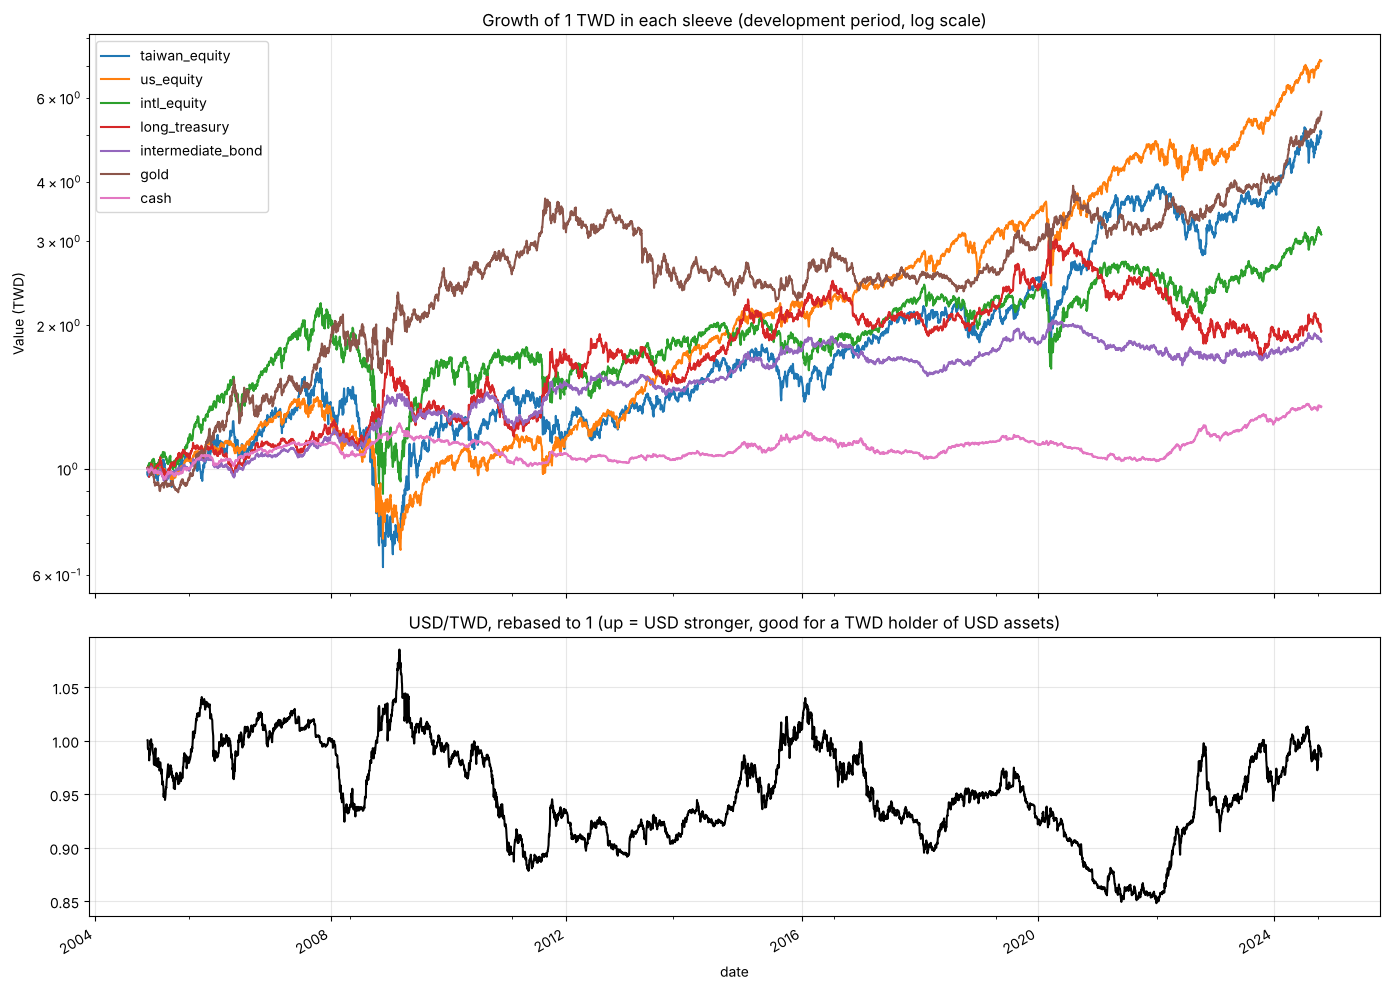

,taiwan_equity,us_equity,intl_equity,long_treasury,intermediate_bond,gold,cash
taiwan_equity,1.00,0.70,0.82,-0.27,-0.29,0.05,-0.17
us_equity,0.70,1.00,0.87,-0.27,-0.20,0.05,0.08
intl_equity,0.82,0.87,1.00,-0.30,-0.27,0.14,-0.06
long_treasury,-0.27,-0.27,-0.30,1.00,0.89,0.21,0.35
intermediate_bond,-0.29,-0.20,-0.27,0.89,1.00,0.26,0.59
gold,0.05,0.05,0.14,0.21,0.26,1.00,0.15
cash,-0.17,0.08,-0.06,0.35,0.59,0.15,1.00


In [6]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={"height_ratios": [2, 1]}, sharex=True)
((1 + data.returns).cumprod()).plot(ax=axes[0], logy=True)
axes[0].set_title("Growth of 1 TWD in each sleeve (development period, log scale)")
axes[0].set_ylabel("Value (TWD)")
axes[0].grid(True, alpha=0.3)
((1 + data.fx).cumprod()).plot(ax=axes[1], color="black")
axes[1].set_title("USD/TWD, rebased to 1 (up = USD stronger, good for a TWD holder of USD assets)")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

data.returns.corr().style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)

## Step 3: Baseline backtests

Each benchmark is rebalanced back to its target weights on the last trading day of every quarter. The first rebalance buys the portfolio from cash and pays for it. Within each estimation window all methods start on the same day, so they are compared over exactly the same period. (The benchmarks do not estimate anything, so their 3-year and 5-year rows differ only in start date.)

Costs come from the `costs` section of the config. They are assumptions to be checked against fact sheets before the final run:

In [7]:
costs = CostModel.from_config(cfg, list(data.returns.columns))
costs.as_frame().style.format("{:.3%}")

,holding_per_year,buy_cost,sell_cost
taiwan_equity,-0.160%,0.135%,0.235%
us_equity,0.910%,0.235%,0.335%
intl_equity,0.590%,0.285%,0.386%
long_treasury,0.100%,0.235%,0.335%
intermediate_bond,0.150%,0.285%,0.386%
gold,0.600%,0.235%,0.335%
cash,0.000%,0.000%,0.000%


In [8]:
results = run_experiment(cfg, data)
summary = summary_table(results, data, cfg)

pct = ["ann_return", "ann_vol", "max_drawdown", "cvar95_daily", "cvar95_monthly",
       "turnover_per_year", "tracking_error", "cost_drag_per_year"]
summary.style.format({**{c: "{:.2%}" for c in pct},
                      "sharpe": "{:.2f}", "sortino": "{:.2f}", "calmar": "{:.2f}"}, na_rep="-")

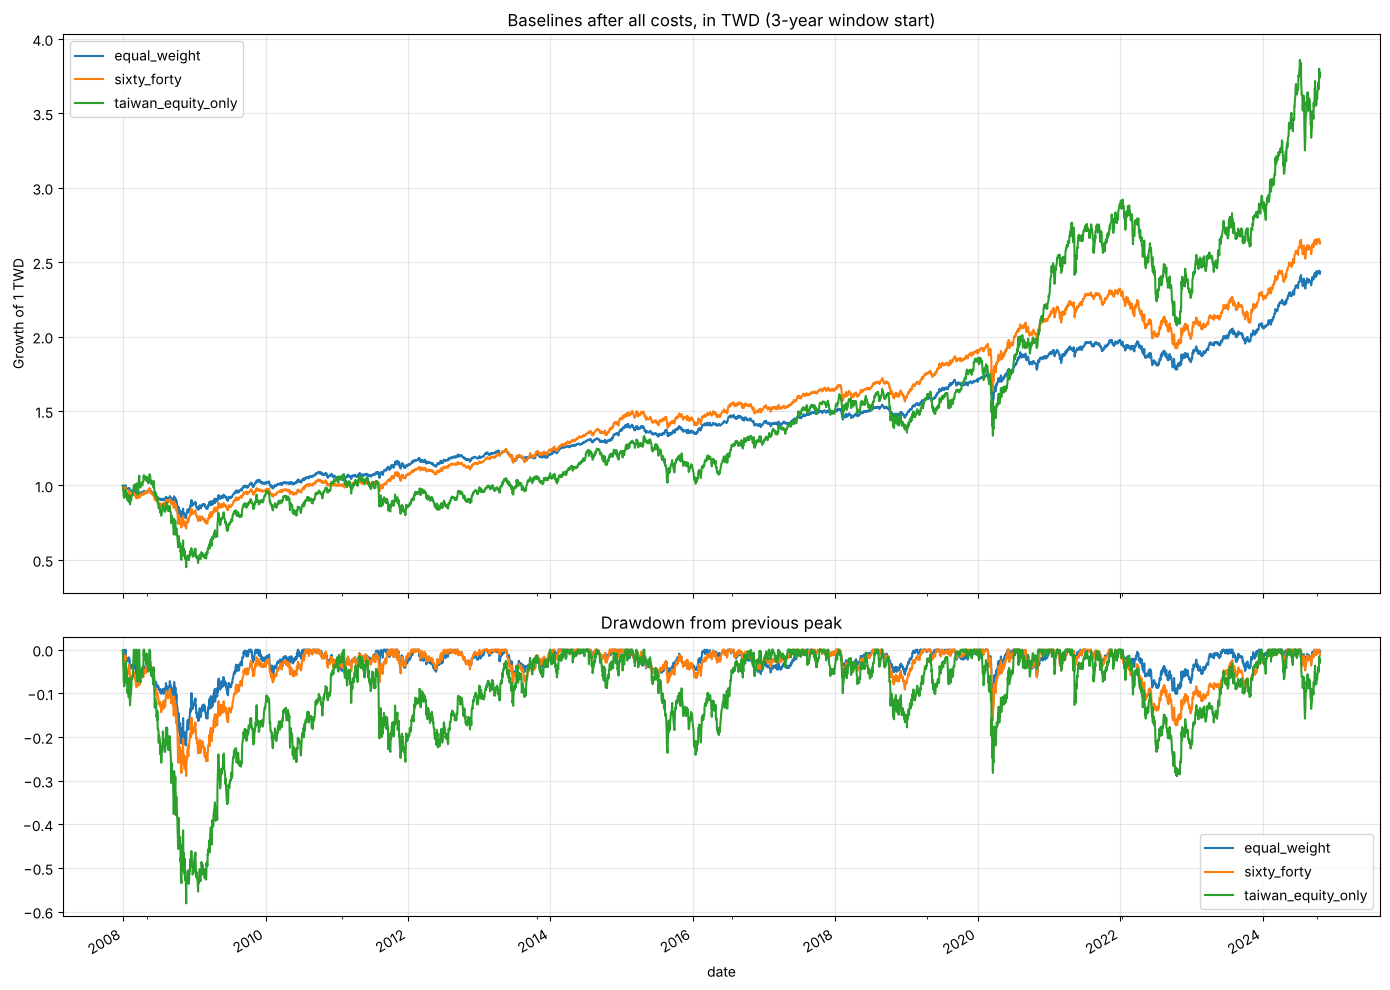

In [9]:
w = cfg["backtest"]["window_years"][0]
fig, axes = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={"height_ratios": [2, 1]}, sharex=True)
for (win, name), res in results.items():
    if win != w:
        continue
    (1 + res.returns).cumprod().plot(ax=axes[0], label=name)
    metrics.drawdown(res.returns).plot(ax=axes[1], label=name)
axes[0].set_title(f"Baselines after all costs, in TWD ({w}-year window start)")
axes[0].set_ylabel("Growth of 1 TWD")
axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].set_title("Drawdown from previous peak")
axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# What costs took away: return before costs vs after, per year.
cost_view = pd.DataFrame({
    "gross_ann_return": {n: metrics.cagr(r.gross_returns) for (win, n), r in results.items() if win == w},
    "net_ann_return": {n: metrics.cagr(r.returns) for (win, n), r in results.items() if win == w},
    "trading_costs_total": {n: r.trading_costs.sum() for (win, n), r in results.items() if win == w},
})
cost_view["drag"] = cost_view["gross_ann_return"] - cost_view["net_ann_return"]
cost_view.style.format("{:.2%}")

,gross_ann_return,net_ann_return,trading_costs_total,drag
equal_weight,5.83%,5.44%,1.01%,0.40%
sixty_forty,6.34%,5.93%,1.18%,0.41%
taiwan_equity_only,8.06%,8.22%,0.14%,-0.16%


In [11]:
run_dir = save_run(results, summary, cfg, data)
print("Saved to", run_dir)
print(open(run_dir / "run.json").read()[:600])

Saved to results/phase1_baseline_3e6527ffbfbb_570bdef9e8ea_dev
{
  "created_utc": "2026-10-23T15:47:33+00:00",
  "config_name": "phase1_baseline",
  "config_hash": "3e6527ffbfbb",
  "config_file": "configs/phase1_baseline.yaml",
  "snapshot_id": "570bdef9e8ea",
  "seed": 42,
  "includes_holdout": false,
  "holdout_start": "2024-10-23",
  "data_first": "2004-11-22",
  "data_last": "2024-10-22",
  "package_version": "0.1.0",
  "python": "3.13.17",
  "numpy": "2.5.3",
  "pandas": "3.0.5",
  "config": {
    "name": "phase1_baseline",
    "seed": 42,
    "base_currency": "TWD",
    "data": {
      "snapshot_dir": "data/snapshots/latest",
      "start": "2004-1


## Step 4: Reproducibility check (the Phase 1 gate)

Rebuild everything from the frozen snapshot and check that every number is identical, to the last bit.

In [12]:
data2 = load_market_data(load_config("configs/phase1_baseline.yaml"), snapshot_dir=SNAPSHOT)
summary2 = summary_table(run_experiment(cfg, data2), data2, cfg)
pd.testing.assert_frame_equal(summary, summary2, check_exact=True)
print("Identical: baseline numbers reproduce exactly from the snapshot.")

Identical: baseline numbers reproduce exactly from the snapshot.


## Findings

*From the run above (snapshot `570bdef9e8ea`, development data to 22 Oct 2024, 3-year window start 31 Dec 2007).*

- Equal weight: 5.4% a year, volatility 8.9%, Sharpe 0.51, max drawdown -21.9%. 60/40: 5.9%, 11.3%, 0.47, -28.9%. 100% Taiwan equity: 8.2%, 23.6%, 0.41, -58.1%.
- Equal weight had a higher Sharpe and a smaller drawdown than 60/40, and 100% Taiwan equity earned the most but lost 58% at its worst.
- Costs and taxes took about 0.4% a year from the two diversified baselines. For 100% Taiwan equity the drag is slightly negative, because the assumed 0050 fee is below EWT's (an assumption to verify).
- In TWD, the cash sleeve's worst drawdown was -18.8%: it is a US T-bill converted to TWD, so it carries USD/TWD risk a TWD deposit would not have.

## FINAL: hold-out evaluation (do not run during development)

This cell opens the locked last two years. The plan is to open it **once, at the end of Phase 3**, for all methods together, so leave `RUN_HOLDOUT = False` here. Every opening is logged in `results/holdout_log.jsonl`.

In [13]:
RUN_HOLDOUT = False

if RUN_HOLDOUT:
    from portfolio_engine.backtest import evaluate_holdout
    holdout_summary, holdout_results, holdout_dir = evaluate_holdout(cfg, snapshot_dir=SNAPSHOT)
    print("Saved to", holdout_dir)
    display(holdout_summary)
else:
    print("Hold-out still locked.")

Hold-out still locked.
